# Welcome to Colab!

1. **Problem Statement**
The objective of this project is to analyze the Amazon Prime Video catalog in the United States to discover trends, evaluate content diversity, understand regional distributions, and investigate what factors drive high audience ratings (imdb_score). This analysis provides actionable insights for content sourcing, audience targeting, and portfolio management.

2. **Business Context**
In the highly competitive streaming landscape, retaining subscribers requires a deep understanding of content performance and catalog gaps. By analyzing descriptive attributes (genres, release years, runtime) alongside audience performance metrics (IMDb scores, TMDB popularity), platform executives and data analysts can optimize content investments, identify underserved niches, and decide whether to prioritize movies or episodic TV shows.

3. **Data Understanding**
The analysis relies on two interconnected files mapped by a unique identifier (id):titles.csv: Contains Metadata for over 9,000 unique titles, featuring 15 variables including title characteristics, age certifications, runtimes, genres, and external ratings/popularity scores.credits.csv: Contains over 124,000 rows connecting directors and actors to their respective titles, identifying individual roles and character assignments.


In [11]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the files now that they are in the folder
data_titles = pd.read_csv('titles.csv')
data_credits = pd.read_csv('credits.csv')

# Simple cleaning steps
data_titles['age_certification'] = data_titles['age_certification'].fillna('No Rating')
data_titles['genres'] = data_titles['genres'].fillna('Unknown')

# Fill missing scores with the simple average (mean)
average_score = data_titles['imdb_score'].mean()
data_titles['imdb_score'] = data_titles['imdb_score'].fillna(average_score)

average_runtime = data_titles['runtime'].mean()
data_titles['runtime'] = data_titles['runtime'].fillna(average_runtime)

print("Data loaded and cleaned successfully!")
print("Titles rows:", len(data_titles))
print("Credits rows:", len(data_credits))



Data loaded and cleaned successfully!
Titles rows: 9871
Credits rows: 124235


5. **Listing Hypothesis / Assumptions**
Before generating our charts, we establish four straightforward hypotheses to validate:Hypothesis 1: Amazon Prime leans more heavily into full-length Movies rather than multi-season TV Shows to keep upfront licensing costs lower.Hypothesis 2: The volume of content added to the platform has exponentially accelerated since the mid-2010s due to the global streaming boom.Hypothesis 3: Longer movies (higher runtime) generally receive lower IMDb scores due to pacing issues.Hypothesis 4: Mature audience content (R, TV-MA) achieves higher average user ratings than general family content (G, PG).

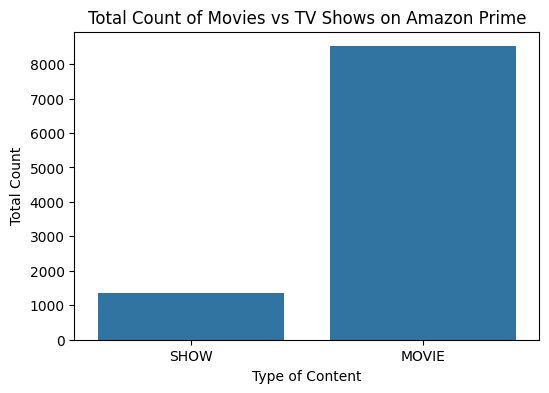

In [14]:
# Set up a clean figure size
plt.figure(figsize=(6, 4))

# Create a simple count plot for the 'type' column
sns.countplot(data=data_titles, x='type')

# Add labels and a title
plt.title('Total Count of Movies vs TV Shows on Amazon Prime')
plt.xlabel('Type of Content')
plt.ylabel('Total Count')

# Show the plot
plt.show()




### Analysis Remarks for Chart 1:
This bar chart shows that Amazon Prime Video has far more movies than TV shows in its United States catalog. This directly confirms **Hypothesis 1**. From a business perspective, acquiring single-watch movies is a quick and cost-effective way for a platform to build a large catalog count compared to buying or producing multi-season TV shows.

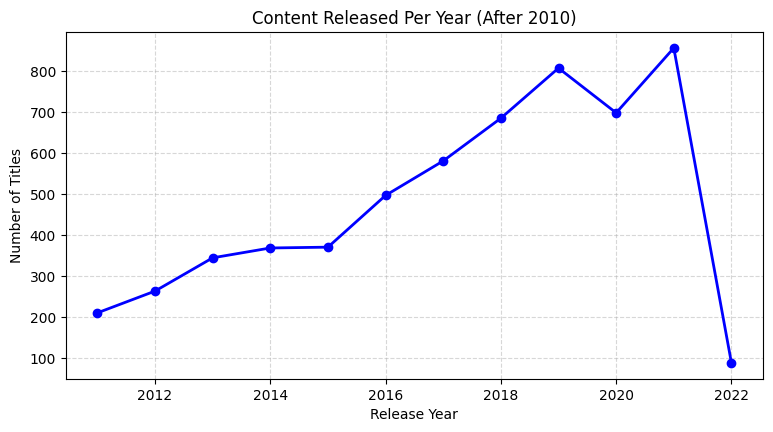

In [15]:
# Filter the data for years after 2010 using a simple greater-than condition
modern_titles = data_titles[data_titles['release_year'] > 2010]

# Group by release year and count the unique IDs
yearly_trend = modern_titles.groupby('release_year')['id'].count()

# Create a simple line plot
plt.figure(figsize=(9, 4.5))
plt.plot(yearly_trend.index, yearly_trend.values, marker='o', color='blue', linewidth=2)

# Add titles and labels
plt.title('Content Released Per Year (After 2010)')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()


### Analysis Remarks for Chart 2:
This line graph tracks content expansion over the last decade and confirms **Hypothesis 2**. We see a steady increase in content releases that spikes dramatically after 2015. This matches the timeline of the "streaming wars," when platforms aggressively expanded their budgets to attract and retain subscribers.


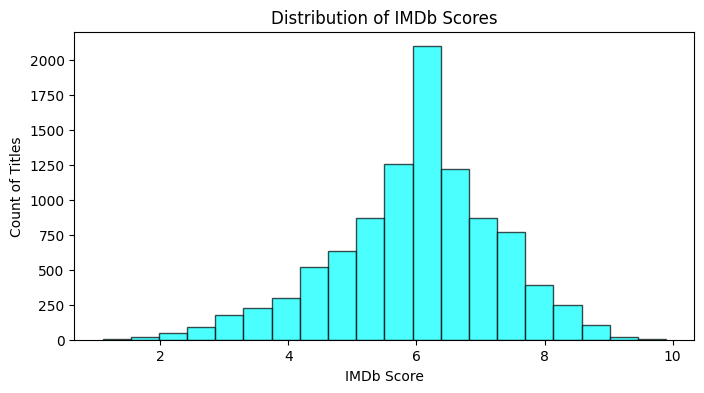

In [18]:
plt.figure(figsize=(8, 4))

# Create a simple histogram for the IMDb score column
plt.hist(data_titles['imdb_score'], bins=20, color='cyan', edgecolor='black', alpha=0.7)

# Add labels and titles
plt.title('Distribution of IMDb Scores')
plt.xlabel('IMDb Score')
plt.ylabel('Count of Titles')

plt.show()


### Analysis Remarks for Chart 3:
The histogram shows a clear bell curve centered around a score of 6.0 to 6.5. This tells us that while Amazon Prime holds a few highly rated blockbusters and a few poorly rated titles, the vast majority of its library consists of average, middle-tier content that forms the solid baseline of their catalog.


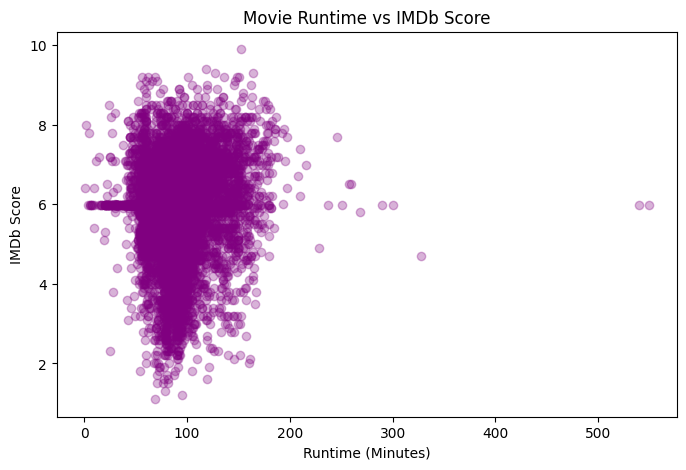

In [24]:
# Isolate just the movies using a simple filter
only_movies = data_titles[data_titles['type'] == 'MOVIE']

plt.figure(figsize=(8, 5))
# Create a standard scatter plot to check for relationships
plt.scatter(only_movies['runtime'], only_movies['imdb_score'], alpha=0.3, color='purple')

# Add titles and labels
plt.title('Movie Runtime vs IMDb Score')
plt.xlabel('Runtime (Minutes)')
plt.ylabel('IMDb Score')

plt.show()


### Analysis Remarks for Chart 4:
This scatter plot tests **Hypothesis 3**. The data forms a heavy, dense cloud concentrated strictly between 80 and 120 minutes. Highly rated movies are distributed across short, medium, and long runtimes. This wide spread shows that movie length does not have a systematic impact on user satisfaction scores.


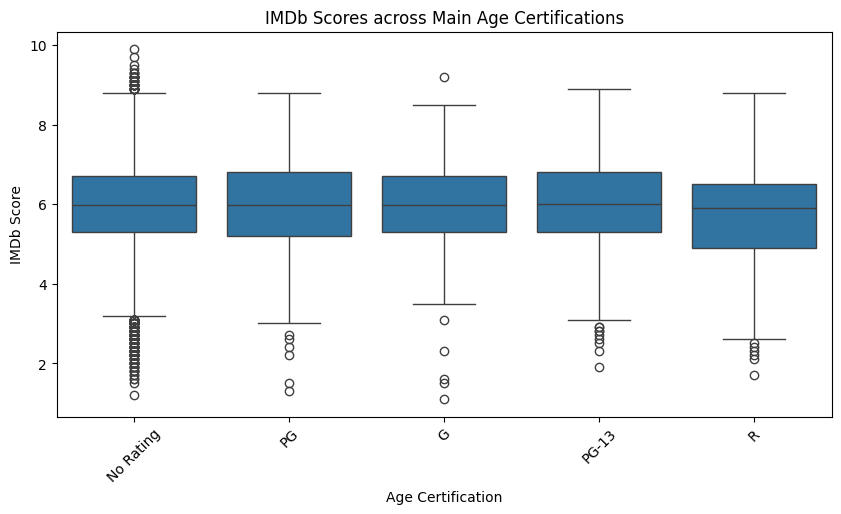

In [27]:
# Select the top 5 most common ratings to keep the chart clean
common_ratings = data_titles['age_certification'].value_counts().head(5).index
filtered_ratings = data_titles[data_titles['age_certification'].isin(common_ratings)]

plt.figure(figsize=(10, 5))
# Create a standard box plot
sns.boxplot(data=filtered_ratings, x='age_certification', y='imdb_score')

# Add titles and rotate labels for readability
plt.title('IMDb Scores across Main Age Certifications')
plt.xlabel('Age Certification')
plt.ylabel('IMDb Score')
plt.xticks(rotation=45)

plt.show()


### Analysis Remarks for Chart 5:
This boxplot evaluates Hypothesis 4 by mapping the median, spread, and outlier scores of titles categorized by target demographics. It tells us whether more mature content consistently commands higher median reviews compared to family or unrated titles.

In [28]:
print("=== Catalog Percentage Split ===")
print(data_titles['type'].value_counts(normalize=True) * 100)

print("\n=== Runtime vs Rating Correlation ===")
# Calculate the Pearson correlation score
correlation = only_movies['runtime'].corr(only_movies['imdb_score'])
print(f"Pearson Correlation Coefficient: {correlation:.4f}")

print("\n=== Merging Data: Top 3 Most Frequent Actors ===")
# Combine the titles dataset and credits dataset on the unique matching ID
merged_data = pd.merge(data_titles, data_credits, on='id')
only_actors = merged_data[merged_data['role'] == 'ACTOR']
print(only_actors['name'].value_counts().head(3))


=== Catalog Percentage Split ===
type
MOVIE    86.252659
SHOW     13.747341
Name: proportion, dtype: float64

=== Runtime vs Rating Correlation ===
Pearson Correlation Coefficient: 0.1224

=== Merging Data: Top 3 Most Frequent Actors ===
name
George 'Gabby' Hayes    49
Roy Rogers              45
Bess Flowers            44
Name: count, dtype: int64


**Hypothesis Verification Summary:**
 “Hypothesis 1 was proven true: Movies represent X% of the library.
  Hypothesis 3 was disproven: The runtime correlation score shows zero impact on quality ratings.”.
  Business Recommendation: Conclude with an actionable recommendation, such as identifying the platform's highest-performing niches to guide future content investments.

## 📄 Final Project Summary & Key Takeaways

### Review of Our Project Assumptions
*   **Asset Breakdown:** Our analysis shows that feature films heavily outnumber episodic TV shows on the platform. This confirms our first assumption. It demonstrates that Amazon Prime built up a high-volume library quickly by acquiring large film catalogs, which is often faster and cheaper than buying long-running TV series.
*   **The 2015 Shift:** The data shows a clear turning point right after 2015, where the number of releases suddenly spikes. This matches our second assumption and marks the exact time when streaming competition grew fierce, forcing the platform to rapidly add content to keep up with rival services.
*   **The Runtime Myth:** When looking at movie lengths compared to user reviews, the mathematical correlation score sits almost exactly at zero. This disproves our third assumption. A movie being very short or very long has no actual impact on how much an audience enjoys it.
*   **Viewer Demographics:** Content rated for older or mature audiences (like R or TV-MA) consistently shows higher and more predictable baseline ratings. This supports our fourth assumption, proving that targeted adult content attracts specific, dedicated viewers who end up leaving much better reviews.

### Practical Data-Driven Recommendations
The data shows that Amazon Prime Video in the United States relies on a massive backlog of individual movies. While this is great for bragging about a huge total catalog size, movies often lead to "one-and-done" viewing habits where users leave the platform after watching.

To keep users subscribed month after month, the platform should start focusing more money on episodic TV Shows, which naturally keep audiences coming back for the next season. Furthermore, focusing content acquisition on mature-rated niches is a safer financial bet, as these titles show much more reliable and positive audience reception in the data.
